## Bài 

In [1]:
import pandas as pd 
import numpy as np

math = pd.read_csv("student-mat.csv", sep = ";")
por = pd.read_csv("student-por.csv", sep = ";")
df = pd.concat([math, por], ignore_index = True)
print(df)

     school sex  age address famsize Pstatus  Medu  Fedu      Mjob      Fjob  \
0        GP   F   18       U     GT3       A     4     4   at_home   teacher   
1        GP   F   17       U     GT3       T     1     1   at_home     other   
2        GP   F   15       U     LE3       T     1     1   at_home     other   
3        GP   F   15       U     GT3       T     4     2    health  services   
4        GP   F   16       U     GT3       T     3     3     other     other   
...     ...  ..  ...     ...     ...     ...   ...   ...       ...       ...   
1039     MS   F   19       R     GT3       T     2     3  services     other   
1040     MS   F   18       U     LE3       T     3     1   teacher  services   
1041     MS   F   18       U     GT3       T     1     1     other     other   
1042     MS   M   17       U     LE3       T     3     1  services  services   
1043     MS   M   18       R     LE3       T     3     2  services     other   

      ... famrel freetime  goout  Dalc 

In [2]:
df.head()

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


# Sài attrs

In [3]:
df.attrs["col_type"] = {
        "Định lượng rời rạc" : ["age", "absences", "G1", "G2", "G3"],
        "Định lượng liên tục" : [],
        "Định tính" : [ 
            "school", "sex", "address", "famsize", "Pstatus",
            "Mjob", "Fjob", "reason", "guardian",
            "schoolsup", "famsup", "paid", "activities",
            "nursery", "higher", "internet", "romantic",],
        "Định tính có thứ tự" : [
                                "Medu", "Fedu", "traveltime", "studytime",
                                 "famrel", "freetime", "goout", "Dalc", "Walc", "health",],
}

In [4]:
df.attrs

{'col_type': {'Định lượng rời rạc': ['age', 'absences', 'G1', 'G2', 'G3'],
  'Định lượng liên tục': [],
  'Định tính': ['school',
   'sex',
   'address',
   'famsize',
   'Pstatus',
   'Mjob',
   'Fjob',
   'reason',
   'guardian',
   'schoolsup',
   'famsup',
   'paid',
   'activities',
   'nursery',
   'higher',
   'internet',
   'romantic'],
  'Định tính có thứ tự': ['Medu',
   'Fedu',
   'traveltime',
   'studytime',
   'famrel',
   'freetime',
   'goout',
   'Dalc',
   'Walc',
   'health']}}

## Vẽ boxplot G3 cho MS và GP

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns 

## Cách 1: Seaborn

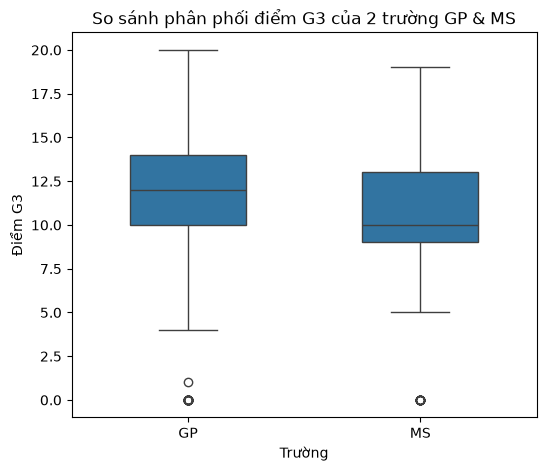

In [11]:
plt.figure(figsize = (6, 5))
sns.boxplot(data = df, x= "school", y = "G3", width = 0.5)
plt.title("So sánh phân phối điểm G3 của 2 trường GP & MS")
plt.xlabel("Trường")
plt.ylabel("Điểm G3")
plt.show()

## Cách 2: Dùng matplotlib.pyplot.boxplot

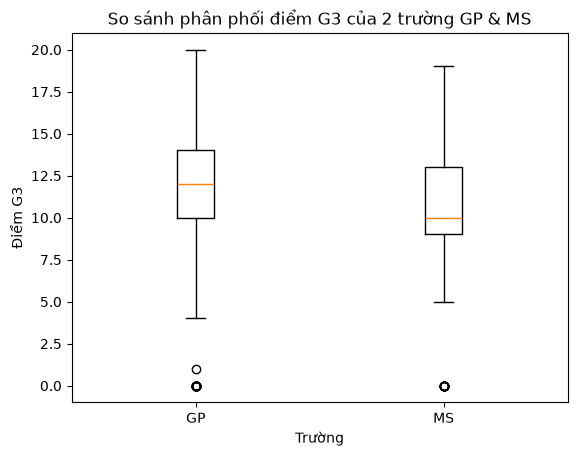

In [26]:
gp = df[df["school"] == "GP" ]["G3"]
ms = df[df["school"] == "MS" ]["G3"]

plt.boxplot([gp, ms], tick_labels = ["GP", "MS"])
plt.title("So sánh phân phối điểm G3 của 2 trường GP & MS")
plt.xlabel("Trường")
plt.ylabel("Điểm G3")
plt.show()


## Cách 3: Series

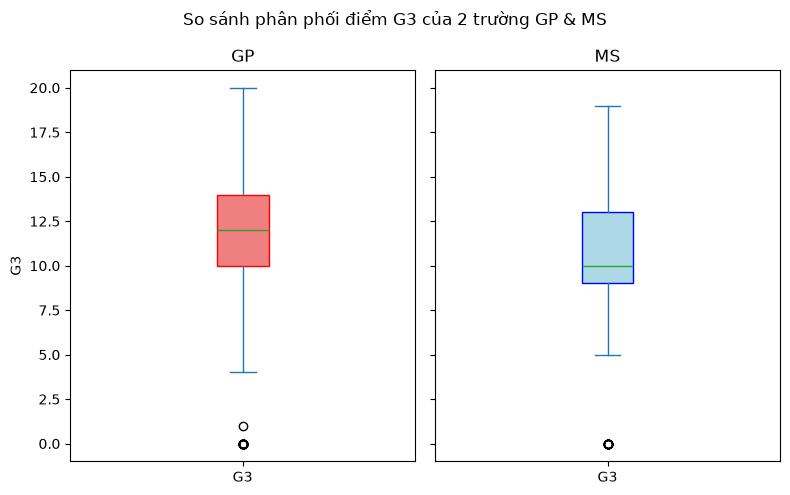

In [27]:
fig, axes = plt.subplots(1, 2, figsize = (8,5), sharey = True)

gp.plot(kind = "box", ax = axes[0], patch_artist = True,
        boxprops = dict(facecolor = "lightcoral", color = "red"))
axes[0].set_title("GP")
axes[0].set_ylabel("G3")

ms.plot(kind = "box", ax=axes[1], patch_artist = True,
        boxprops = dict(facecolor = "lightblue", color = "blue"))
axes[1].set_title("MS")

fig.suptitle("So sánh phân phối điểm G3 của 2 trường GP & MS")
plt.tight_layout()
plt.show()